## Chapter 4 - Estimating Price Response

### Exercise 1:
For the three price-response functions listed in Table 4.4—linear, exponential, 
and constant-elasticity—fit a model on the training data in Table 4.2 that includes 
Weekend as an explanatory variable along with Price.

a. What are the coefficients for Price and Weekend in each model?

b. Calculate RMSE, MAPE, and weighted MAPE for the models on the test data in 
Table 4.3 including Weekend. How do the fits of the models including Weekend 
compare to the fits of the previous models? Which model best fits the data?

---

#### Summary

**Process:** fit the linear ($d = \beta_0 + \beta_p\,p + \beta_w\,w$), exponential ($\ln d = \beta_0 + \beta_p\,p + \beta_w\,w$) and constant-elasticity ($\ln d = \beta_0 + \beta_p \ln p + \beta_w\,w$) models on the training set with linear regression, with and without Weekend. Then predict test sales and compute RMSE, MAPE and weighted MAPE.

**(a)** The coefficients (Price, Weekend) were found to be: linear $-26.82$, $12.83$; exponential $-1.750$, $0.648$; constant-elasticity $-11.90$, $0.649$.

**(b)** The test set metrics of the best model, linear with Weekend, were found to be RMSE = 6.82, MAPE = 0.27, weighted MAPE = 0.24.

**Conclusion:** adding Weekend improves all three metrics for every model, by about 18–26%. The linear model with Weekend fits best.

---

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

In [106]:
# Importing the training and test datasets as pandas DataFrames
train_set = pd.read_csv("table4.2.csv")
test_set = pd.read_csv("table4.3.csv")

# Displaying the first 10 rows of the training and test datasets for verification
print("Number of rows and columns:", train_set.shape)
print(train_set.head(10))
print("Number of rows and columns:", test_set.shape)
print(test_set.head(10))

Number of rows and columns: (42, 5)
   day  price  sales  weekend  potential
0    1   6.45     49        1         52
1    2   6.55     40        1         41
2    3   6.65     24        0         31
3    4   6.75     25        0         34
4    5   6.85     18        0         27
5    6   6.95     31        0         49
6    7   7.05     17        0         37
7    8   7.15     19        1         52
8    9   7.25      4        1         22
9   10   7.15     11        0         37
Number of rows and columns: (21, 5)
   day  price  sales  weekend  potential
0    1   6.45     52        1         56
1    2   6.55     49        1         55
2    3   6.65     34        0         39
3    4   6.75     15        0         27
4    5   6.85     17        0         27
5    6   6.95     17        0         22
6    7   7.05      6        0         32
7    8   7.15     24        1         66
8    9   7.25     15        1         42
9   10   7.15     13        0         30


The three price-response functions are

* Linear: $d(p) = D(1-bp)^+$
* Exponential: $d(p) = De^{-bp}$
* Constant-elasticity: $d(p) = Ap^{-\varepsilon}$


**First let's fit the three models on the training set considering only price and sales:**

In [107]:
# Creating variables for the training set data
X_train = train_set[["price"]]
y_train = train_set["sales"]
X_log_train = np.log(X_train)
y_log_train = np.log(y_train)

In [108]:
print("Linear model")

# Fitting a linear regression to the linear model training data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Getting the coefficients of the linear regression
print("Intercept:", linear_model.intercept_)
print("Price coefficient:", linear_model.coef_[0])

# Finding the parameters D and b of the linear model
D_lin = linear_model.intercept_
print("D =", D_lin)
b_lin = - linear_model.coef_[0] / D_lin
print("b =", b_lin)

# Finding the R-squared value of the linear regression model on the training data
r_squared_lin = linear_model.score(X_train, y_train)
print("R-squared:", r_squared_lin)

Linear model
Intercept: 222.01920087775446
Price coefficient: -29.496205540824725
D = 222.01920087775446
b = 0.1328543000975198
R-squared: 0.3500653339515143


In [109]:
print("Exponential model")

# Fitting a linear regression to the exponential model training data
exponential_model = LinearRegression()
exponential_model.fit(X_train, y_log_train)

# Getting the coefficients of the linear regression
print("Intercept:", exponential_model.intercept_)
print("Price coefficient:", exponential_model.coef_[0])

# Finding the parameters D and b of the exponential model
D_exp = np.exp(exponential_model.intercept_)
print("D =", D_exp)
b_exp = - exponential_model.coef_[0]
print("b =", b_exp)

# Finding the R-squared value of the exponential linear regression on the training data
r_squared_exp = exponential_model.score(X_train, y_log_train)
print("R-squared:", r_squared_exp)


Exponential model
Intercept: 15.649337437028873
Price coefficient: -1.8847829000952538
D = 6257788.694799975
b = 1.8847829000952538
R-squared: 0.3316951616726187


In [110]:
print("Constant-elasticity model")

# Fitting a linear regression to the constant-elasticity model training data
constant_elasticity_model = LinearRegression()
constant_elasticity_model.fit(X_log_train, y_log_train)

# Getting the coefficients of the linear regression
print("Intercept:", constant_elasticity_model.intercept_)
print("Price coefficient:", constant_elasticity_model.coef_[0])

# Finding the parameters A and epsilon of the constant-elasticity model
A_ce = np.exp(constant_elasticity_model.intercept_)
print("A =", A_ce)
epsilon_ce = - constant_elasticity_model.coef_[0]
print("epsilon =", epsilon_ce)

# Finding the R-squared value of the constant-elasticity linear regression on the training data
r_squared_ce = constant_elasticity_model.score(X_log_train, y_log_train)
print("R-squared:", r_squared_ce)

Constant-elasticity model
Intercept: 27.40116746549102
Price coefficient: -12.821217118665512
A = 794649890657.5829
epsilon = 12.821217118665512
R-squared: 0.3260404685629025


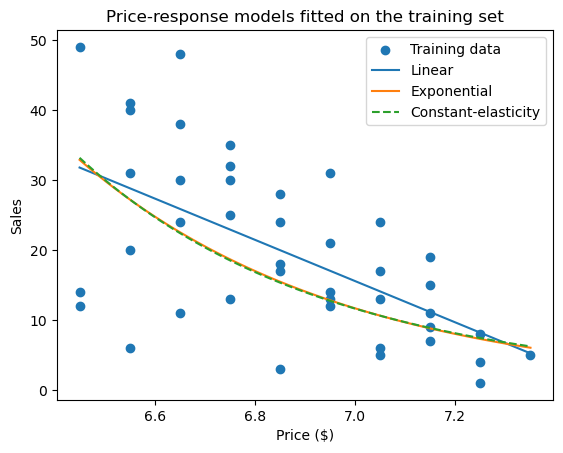

In [111]:
# Creating a range of prices for plotting the fitted models
prices = np.linspace(train_set["price"].min(), train_set["price"].max(), 100)

# Linear model
linear_curve = D_lin * (1 - b_lin * prices)

# Exponential model: back to actual demand
exp_curve = D_exp * np.exp(-b_exp * prices)

# Constant-elasticity model: back to actual demand
ce_curve = A_ce * prices ** (-epsilon_ce)

plt.scatter(train_set["price"], train_set["sales"], label="Training data")
plt.plot(prices, linear_curve, label="Linear")
plt.plot(prices, exp_curve, label="Exponential")
plt.plot(prices, ce_curve, linestyle="--", label="Constant-elasticity")
plt.xlabel("Price ($)")
plt.ylabel("Sales")
plt.title("Price-response models fitted on the training set")
plt.legend()
plt.show()

**Now let's test the models on the test set:**

In [112]:
# Creating variables for the test set data
X_test = test_set[["price"]]
y_test = test_set["sales"]
X_log_test = np.log(X_test)
# y_log_test is not needed: predictions are compared with actual sales in original units

In [113]:
# Creating the predictions for the test set data for each model
linear_predictions = linear_model.predict(X_test)
exponential_predictions = np.exp(exponential_model.predict(X_test))
constant_elasticity_predictions = np.exp(constant_elasticity_model.predict(X_log_test))

# Creating a predictions table to compare the actual sales and the predictions from each model
predictions_table = pd.DataFrame({
    "day": test_set["day"],
    "actual sales": test_set["sales"],
    "linear predictions": linear_predictions,
    "exponential predictions": exponential_predictions,
    "constant-elasticity predictions": constant_elasticity_predictions
})
predictions_table.round(2)

,day,actual sales,linear predictions,exponential predictions,constant-elasticity predictions
0,1,52,31.77,32.87,33.16
1,2,49,28.82,27.22,27.23
2,3,34,25.87,22.55,22.42
3,4,15,22.92,18.67,18.51
4,5,17,19.97,15.46,15.33
5,6,17,17.02,12.81,12.73
6,7,6,14.07,10.61,10.60
7,8,24,11.12,8.79,8.85
8,9,15,8.17,7.28,7.41
9,10,13,11.12,8.79,8.85


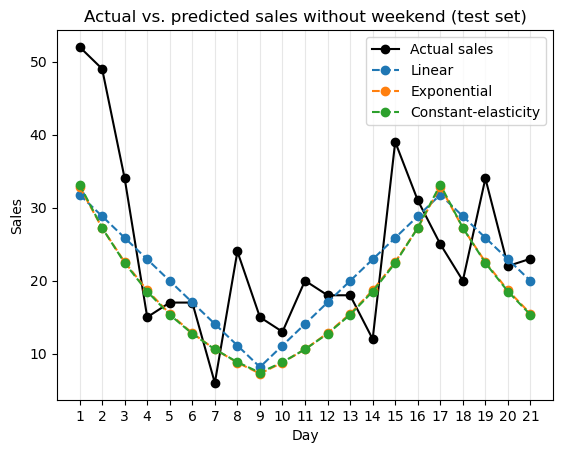

In [114]:
# Plotting actual sales and predictions of the models without weekend for each day of the test set
plt.plot(test_set["day"], test_set["sales"], "o-", color="black", label="Actual sales")
plt.plot(test_set["day"], linear_predictions, "o--", label="Linear")
plt.plot(test_set["day"], exponential_predictions, "o--", label="Exponential")
plt.plot(test_set["day"], constant_elasticity_predictions, "o--", label="Constant-elasticity")
plt.xticks(test_set["day"])
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Day")
plt.ylabel("Sales")
plt.title("Actual vs. predicted sales without weekend (test set)")
plt.legend()
plt.show()

**And evaluate the predictions using three metrics:**

In [115]:
# RMSE: root-mean-square error
rmse_lin = np.sqrt(mean_squared_error(y_test, linear_predictions))

# MAPE: mean absolute percentage error
mape_lin = mean_absolute_percentage_error(y_test, linear_predictions)

# Weighted MAPE: MAPE weighted by actual sales
wmape_lin = np.sum(np.abs(linear_predictions - y_test)) / np.sum(y_test)

print(f"RMSE for the linear model: {rmse_lin:.2f}")
print(f"MAPE for the linear model: {mape_lin:.2f}")
print(f"Weighted MAPE for the linear model: {wmape_lin:.2f}")

RMSE for the linear model: 9.18
MAPE for the linear model: 0.34
Weighted MAPE for the linear model: 0.30


In [116]:
# RMSE: root-mean-square error
rmse_exp = np.sqrt(mean_squared_error(y_test, exponential_predictions))

# MAPE: mean absolute percentage error
mape_exp = mean_absolute_percentage_error(y_test, exponential_predictions)

# Weighted MAPE: MAPE weighted by actual sales
wmape_exp = np.sum(np.abs(exponential_predictions - y_test)) / np.sum(y_test)

print(f"RMSE for the exponential model: {rmse_exp:.2f}")
print(f"MAPE for the exponential model: {mape_exp:.2f}")
print(f"Weighted MAPE for the exponential model: {wmape_exp:.2f}")

RMSE for the exponential model: 10.00
MAPE for the exponential model: 0.36
Weighted MAPE for the exponential model: 0.35


In [117]:
# RMSE: root-mean-square error
rmse_ce = np.sqrt(mean_squared_error(y_test, constant_elasticity_predictions))

# MAPE: mean absolute percentage error
mape_ce = mean_absolute_percentage_error(y_test, constant_elasticity_predictions)

# Weighted MAPE: MAPE weighted by actual sales
wmape_ce = np.sum(np.abs(constant_elasticity_predictions - y_test)) / np.sum(y_test)

print(f"RMSE for the constant-elasticity model: {rmse_ce:.2f}")
print(f"MAPE for the constant-elasticity model: {mape_ce:.2f}")
print(f"Weighted MAPE for the constant-elasticity model: {wmape_ce:.2f}")

RMSE for the constant-elasticity model: 10.00
MAPE for the constant-elasticity model: 0.36
Weighted MAPE for the constant-elasticity model: 0.35


In [118]:
# Performance of each price-response model on the test set (like Table 4.6)
metrics_table = pd.DataFrame({
    "Model": ["Linear", "Exponential", "Constant-elasticity"],
    "RMSE": [rmse_lin, rmse_exp, rmse_ce],
    "MAPE": [mape_lin, mape_exp, mape_ce],
    "Weighted MAPE": [wmape_lin, wmape_exp, wmape_ce],
})
metrics_table.round(2)

,Model,RMSE,MAPE,Weighted MAPE
0,Linear,9.18,0.34,0.30
1,Exponential,10.00,0.36,0.35
2,Constant-elasticity,10.00,0.36,0.35


(**Note on Table 4.6:** The book says the metrics in Table 4.6 are computed on the test set (Table 4.3), but they match the values computed on the **training set** (Table 4.2) exactly. On the test set, the results here are lower, and the linear model is best on all three metrics.)

**Now let's fit again the three models adding "weekend" as a second explanatory variable:**

With weekend ($w = 1$ on weekends, $0$ otherwise), the regressions become:

* Linear: $d = \beta_0 + \beta_p\,p + \beta_w\,w$ (weekend adds $\beta_w$ units)
* Exponential: $\ln d = \beta_0 + \beta_p\,p + \beta_w\,w$ (weekend multiplies demand by $e^{\beta_w}$)
* Constant-elasticity: $\ln d = \beta_0 + \beta_p \ln p + \beta_w\,w$ (weekend multiplies demand by $e^{\beta_w}$)

In [119]:
# Creating variables for the training set data (y variables are the same as before)
X_wknd_train = train_set[["price", "weekend"]]
X_log_wknd_train = X_wknd_train.copy()
X_log_wknd_train["price"] = np.log(X_log_wknd_train["price"])

display(X_wknd_train.head())
display(X_log_wknd_train.head())

,price,weekend
0,6.45,1
1,6.55,1
2,6.65,0
3,6.75,0
4,6.85,0


,price,weekend
0,1.864080,1
1,1.879465,1
2,1.894617,0
3,1.909543,0
4,1.924249,0


In [120]:
print("Linear model with weekend")

# Fitting a linear regression to the linear model training data with price and weekend
linear_model_wknd = LinearRegression()
linear_model_wknd.fit(X_wknd_train, y_train)

# Getting the coefficients of the linear regression
print("Intercept:", linear_model_wknd.intercept_)
print("Price coefficient:", linear_model_wknd.coef_[0])
print("Weekend coefficient:", linear_model_wknd.coef_[1])

# Finding the parameters D and b of the linear model (weekday values, weekend = 0)
D_lin_wknd = linear_model_wknd.intercept_
print("D (weekday) =", D_lin_wknd)
b_lin_wknd = - linear_model_wknd.coef_[0] / D_lin_wknd
print("b =", b_lin_wknd)

# Finding the R-squared value of the linear regression model on the training data
r_squared_lin_wknd = linear_model_wknd.score(X_wknd_train, y_train)
print("R-squared:", r_squared_lin_wknd)

Linear model with weekend
Intercept: 199.99238984736456
Price coefficient: -26.820599299520037
Weekend coefficient: 12.834695377697065
D (weekday) = 199.99238984736456
b = 0.1341080994131311
R-squared: 0.565353467575464


In [121]:
print("Exponential model with weekend")

# Fitting a linear regression to the exponential model training data with price and weekend
exponential_model_wknd = LinearRegression()
exponential_model_wknd.fit(X_wknd_train, y_log_train)

# Getting the coefficients of the linear regression
print("Intercept:", exponential_model_wknd.intercept_)
print("Price coefficient:", exponential_model_wknd.coef_[0])
print("Weekend coefficient:", exponential_model_wknd.coef_[1])

# Finding the parameters D and b of the exponential model (weekday values, weekend = 0)
D_exp_wknd = np.exp(exponential_model_wknd.intercept_)
print("D (weekday) =", D_exp_wknd)
b_exp_wknd = - exponential_model_wknd.coef_[0]
print("b =", b_exp_wknd)

# Weekend demand multiplier
weekend_multiplier_exp = np.exp(exponential_model_wknd.coef_[1])
print("Weekend multiplier:", weekend_multiplier_exp)

# Finding the R-squared value of the exponential linear regression on the training data
r_squared_exp_wknd = exponential_model_wknd.score(X_wknd_train, y_log_train)
print("R-squared:", r_squared_exp_wknd)

Exponential model with weekend
Intercept: 14.537607135918176
Price coefficient: -1.7497405406635869
Weekend coefficient: 0.6477887215369021
D (weekday) = 2058745.0084517745
b = 1.7497405406635869
Weekend multiplier: 1.9113097146436457
R-squared: 0.4589620405179964


In [122]:
print("Constant-elasticity model with weekend")

# Fitting a linear regression to the constant-elasticity model training data with log-price and weekend
constant_elasticity_model_wknd = LinearRegression()
constant_elasticity_model_wknd.fit(X_log_wknd_train, y_log_train)

# Getting the coefficients of the linear regression
print("Intercept:", constant_elasticity_model_wknd.intercept_)
print("Price coefficient:", constant_elasticity_model_wknd.coef_[0])
print("Weekend coefficient:", constant_elasticity_model_wknd.coef_[1])

# Finding the parameters A and epsilon of the constant-elasticity model (weekday values, weekend = 0)
A_ce_wknd = np.exp(constant_elasticity_model_wknd.intercept_)
print("A (weekday) =", A_ce_wknd)
epsilon_ce_wknd = - constant_elasticity_model_wknd.coef_[0]
print("epsilon =", epsilon_ce_wknd)

# Weekend demand multiplier
weekend_multiplier_ce = np.exp(constant_elasticity_model_wknd.coef_[1])
print("Weekend multiplier:", weekend_multiplier_ce)

# Finding the R-squared value of the constant-elasticity linear regression on the training data
r_squared_ce_wknd = constant_elasticity_model_wknd.score(X_log_wknd_train, y_log_train)
print("R-squared:", r_squared_ce_wknd)

Constant-elasticity model with weekend
Intercept: 25.434469912768723
Price coefficient: -11.896069763105297
Weekend coefficient: 0.6492034837100489
A (weekday) = 111185955660.40907
epsilon = 11.896069763105297
Weekend multiplier: 1.9140156770243568
R-squared: 0.4538764728060922


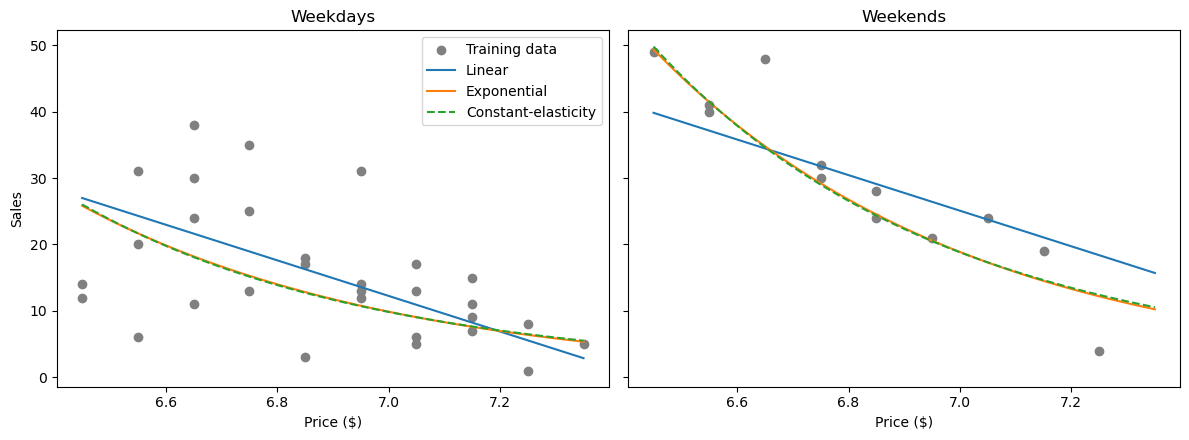

In [123]:
# Creating a range of prices for plotting the fitted models
prices = np.linspace(train_set["price"].min(), train_set["price"].max(), 100)

# Weekday curves (weekend = 0)
linear_wkday = D_lin_wknd * (1 - b_lin_wknd * prices)
exp_wkday = D_exp_wknd * np.exp(-b_exp_wknd * prices)
ce_wkday = A_ce_wknd * prices ** (-epsilon_ce_wknd)

# Weekend curves (weekend = 1)
linear_wkend = linear_wkday + linear_model_wknd.coef_[1]   # adds the weekend units
exp_wkend = exp_wkday * weekend_multiplier_exp             # multiplies by the weekend factor
ce_wkend = ce_wkday * weekend_multiplier_ce                # multiplies by the weekend factor

# Splitting the training data by day type
weekdays = train_set[train_set["weekend"] == 0]
weekends = train_set[train_set["weekend"] == 1]

# Creating two side-by-side panels with the same y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# Left panel: weekdays
ax1.scatter(weekdays["price"], weekdays["sales"], color="gray", label="Training data")
ax1.plot(prices, linear_wkday, label="Linear")
ax1.plot(prices, exp_wkday, label="Exponential")
ax1.plot(prices, ce_wkday, linestyle="--", label="Constant-elasticity")
ax1.set_title("Weekdays")
ax1.set_xlabel("Price ($)")
ax1.set_ylabel("Sales")
ax1.legend()

# Right panel: weekends
ax2.scatter(weekends["price"], weekends["sales"], color="gray", label="Training data")
ax2.plot(prices, linear_wkend, label="Linear")
ax2.plot(prices, exp_wkend, label="Exponential")
ax2.plot(prices, ce_wkend, linestyle="--", label="Constant-elasticity")
ax2.set_title("Weekends")
ax2.set_xlabel("Price ($)")

plt.tight_layout()
plt.show()

**Answer to (a): coefficients of the models with weekend**

| Model | Intercept | Price coefficient | Weekend coefficient |
|---|---|---|---|
| Linear | 199.99 | −26.82 | 12.83 |
| Exponential | 14.54 | −1.750 | 0.648 |
| Constant-elasticity | 25.43 | −11.90 | 0.649 |

In the linear model, a weekend day sells about 12.8 more units at the same price. In the exponential and constant-elasticity models, the weekend coefficient is on log sales: weekend demand is about $e^{0.648} \approx 1.91$ times weekday demand.

**Now let's test the models with weekend on the test set:**

In [124]:
# Creating variables for the test set data (y variables are the same as before)
X_wknd_test = test_set[["price", "weekend"]]
X_log_wknd_test = X_wknd_test.copy()
X_log_wknd_test["price"] = np.log(X_log_wknd_test["price"])

display(X_wknd_test.head())
display(X_log_wknd_test.head())

,price,weekend
0,6.45,1
1,6.55,1
2,6.65,0
3,6.75,0
4,6.85,0


,price,weekend
0,1.864080,1
1,1.879465,1
2,1.894617,0
3,1.909543,0
4,1.924249,0


In [125]:
# Creating the predictions for the test set data for each model with weekend
linear_predictions_wknd = linear_model_wknd.predict(X_wknd_test)
exponential_predictions_wknd = np.exp(exponential_model_wknd.predict(X_wknd_test))
constant_elasticity_predictions_wknd = np.exp(constant_elasticity_model_wknd.predict(X_log_wknd_test))

# Creating a predictions table to compare the actual sales and the predictions from each model with weekend
predictions_table_wknd = pd.DataFrame({
    "day": test_set["day"],
    "weekend": test_set["weekend"],
    "actual sales": test_set["sales"],
    "linear predictions": linear_predictions_wknd,
    "exponential predictions": exponential_predictions_wknd,
    "constant-elasticity predictions": constant_elasticity_predictions_wknd
})
predictions_table_wknd.round(2)

,day,weekend,actual sales,linear predictions,exponential predictions,constant-elasticity predictions
0,1,1,52,39.83,49.38,49.82
1,2,1,49,37.15,41.45,41.49
2,3,0,34,21.64,18.21,18.10
3,4,0,15,18.95,15.28,15.16
4,5,0,17,16.27,12.83,12.72
5,6,0,17,13.59,10.77,10.71
6,7,0,6,10.91,9.04,9.04
7,8,1,24,21.06,14.51,14.63
8,9,1,15,18.38,12.18,12.40
9,10,0,13,8.23,7.59,7.64


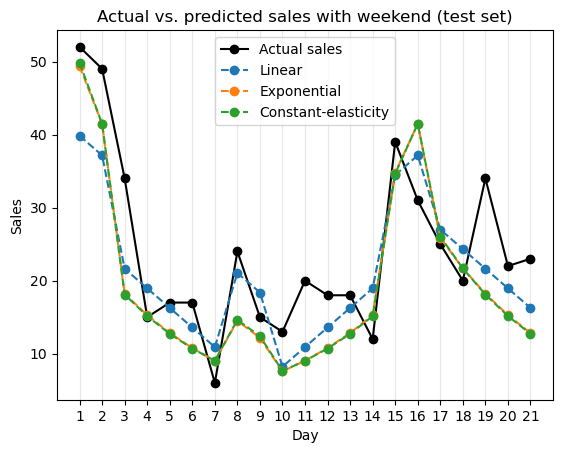

In [126]:
# Plotting actual sales and predictions of the models with weekend for each day of the test set
plt.plot(test_set["day"], test_set["sales"], "o-", color="black", label="Actual sales")
plt.plot(test_set["day"], linear_predictions_wknd, "o--", label="Linear")
plt.plot(test_set["day"], exponential_predictions_wknd, "o--", label="Exponential")
plt.plot(test_set["day"], constant_elasticity_predictions_wknd, "o--", label="Constant-elasticity")
plt.xticks(test_set["day"])
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Day")
plt.ylabel("Sales")
plt.title("Actual vs. predicted sales with weekend (test set)")
plt.legend()
plt.show()

**And evaluate the predictions using three metrics:**

In [127]:
# RMSE: root-mean-square error
rmse_lin_wknd = np.sqrt(mean_squared_error(y_test, linear_predictions_wknd))

# MAPE: mean absolute percentage error
mape_lin_wknd = mean_absolute_percentage_error(y_test, linear_predictions_wknd)

# Weighted MAPE: MAPE weighted by actual sales
wmape_lin_wknd = np.sum(np.abs(linear_predictions_wknd - y_test)) / np.sum(y_test)

print(f"RMSE for the linear model with weekend: {rmse_lin_wknd:.2f}")
print(f"MAPE for the linear model with weekend: {mape_lin_wknd:.2f}")
print(f"Weighted MAPE for the linear model with weekend: {wmape_lin_wknd:.2f}")

RMSE for the linear model with weekend: 6.82
MAPE for the linear model with weekend: 0.27
Weighted MAPE for the linear model with weekend: 0.24


In [128]:
# RMSE: root-mean-square error
rmse_exp_wknd = np.sqrt(mean_squared_error(y_test, exponential_predictions_wknd))

# MAPE: mean absolute percentage error
mape_exp_wknd = mean_absolute_percentage_error(y_test, exponential_predictions_wknd)

# Weighted MAPE: MAPE weighted by actual sales
wmape_exp_wknd = np.sum(np.abs(exponential_predictions_wknd - y_test)) / np.sum(y_test)

print(f"RMSE for the exponential model with weekend: {rmse_exp_wknd:.2f}")
print(f"MAPE for the exponential model with weekend: {mape_exp_wknd:.2f}")
print(f"Weighted MAPE for the exponential model with weekend: {wmape_exp_wknd:.2f}")

RMSE for the exponential model with weekend: 7.70
MAPE for the exponential model with weekend: 0.29
Weighted MAPE for the exponential model with weekend: 0.27


In [129]:
# RMSE: root-mean-square error
rmse_ce_wknd = np.sqrt(mean_squared_error(y_test, constant_elasticity_predictions_wknd))

# MAPE: mean absolute percentage error
mape_ce_wknd = mean_absolute_percentage_error(y_test, constant_elasticity_predictions_wknd)

# Weighted MAPE: MAPE weighted by actual sales
wmape_ce_wknd = np.sum(np.abs(constant_elasticity_predictions_wknd - y_test)) / np.sum(y_test)

print(f"RMSE for the constant-elasticity model with weekend: {rmse_ce_wknd:.2f}")
print(f"MAPE for the constant-elasticity model with weekend: {mape_ce_wknd:.2f}")
print(f"Weighted MAPE for the constant-elasticity model with weekend: {wmape_ce_wknd:.2f}")

RMSE for the constant-elasticity model with weekend: 7.73
MAPE for the constant-elasticity model with weekend: 0.29
Weighted MAPE for the constant-elasticity model with weekend: 0.27


**And now we can finally compare every model, with and without weekend as an explanatory variable:**

In [130]:
# Performance of all six models on the test set
comparison_table = pd.DataFrame({
    "Model": ["Linear", "Exponential", "Constant-elasticity",
              "Linear", "Exponential", "Constant-elasticity"],
    "Variables": ["Price", "Price", "Price",
                  "Price + Weekend", "Price + Weekend", "Price + Weekend"],
    "RMSE": [rmse_lin, rmse_exp, rmse_ce,
             rmse_lin_wknd, rmse_exp_wknd, rmse_ce_wknd],
    "MAPE": [mape_lin, mape_exp, mape_ce,
             mape_lin_wknd, mape_exp_wknd, mape_ce_wknd],
    "Weighted MAPE": [wmape_lin, wmape_exp, wmape_ce,
                      wmape_lin_wknd, wmape_exp_wknd, wmape_ce_wknd],
})
comparison_table.round(2)

,Model,Variables,RMSE,MAPE,Weighted MAPE
0,Linear,Price,9.18,0.34,0.30
1,Exponential,Price,10.00,0.36,0.35
2,Constant-elasticity,Price,10.00,0.36,0.35
3,Linear,Price + Weekend,6.82,0.27,0.24
4,Exponential,Price + Weekend,7.70,0.29,0.27
5,Constant-elasticity,Price + Weekend,7.73,0.29,0.27


**Answer to (b):**

- **Effect of adding Weekend:** all three metrics improved for every model on the test set, by about 18–26%. Since the improvement holds on the test set, Weekend is a useful explanatory variable, not overfitting.

| Model | RMSE | MAPE | Weighted MAPE |
|---|---|---|---|
| Linear | 9.18 → 6.82 | 0.34 → 0.27 | 0.30 → 0.24 |
| Exponential | 10.00 → 7.70 | 0.36 → 0.29 | 0.35 → 0.27 |
| Constant-elasticity | 10.00 → 7.73 | 0.36 → 0.29 | 0.35 → 0.27 |

- **Best model:** the **linear model with Weekend** is best on all three metrics. The exponential and constant-elasticity models perform almost identically.

- **Note:** the differences between functional forms are small compared with the gain from adding Weekend, and the test set has only 21 days, which is a small sample.